In [1]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loaded: stable-diffusion-v1-5/stable-diffusion-v1-5

torch 2.11.0+cu130 | diffusers 0.41.0 | transformers 5.20.1 | peft 0.21.2
UNet parameters: 860 M
Peak GPU memory for inference: 3.42 GB


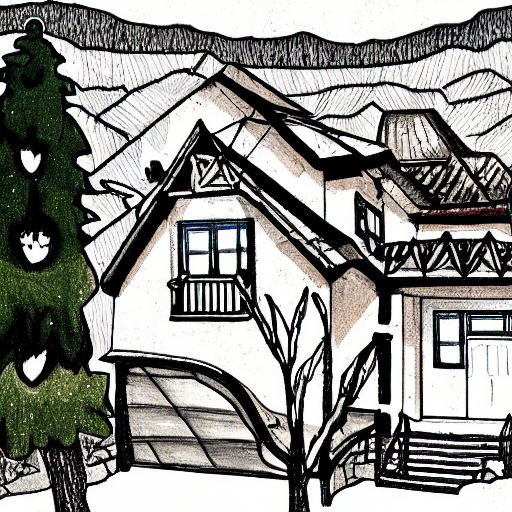

In [2]:
# ============================================================
# LoRA project | Cell 1: install, setup, load base model, first image
# ============================================================
!pip install -q diffusers transformers accelerate peft

import os, random, sys
import numpy as np, torch, diffusers, transformers, peft
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/lora_project'
for sub in ['data', 'outputs', 'lora_weights']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)

device = 'cuda'
assert torch.cuda.is_available(), 'Select a T4 GPU: Runtime > Change runtime type'
print('GPU:', torch.cuda.get_device_name(0))

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)

# ---- Load Stable Diffusion 1.5 (fp16) with an ID fallback ----
from diffusers import StableDiffusionPipeline
MODEL_IDS = ['stable-diffusion-v1-5/stable-diffusion-v1-5', 'runwayml/stable-diffusion-v1-5']
pipe = None
for mid in MODEL_IDS:
    try:
        pipe = StableDiffusionPipeline.from_pretrained(mid, torch_dtype=torch.float16).to(device)
        MODEL_ID = mid
        print('Loaded:', mid)
        break
    except Exception as e:
        print(f'Could not load {mid}: {str(e)[:150]}')
assert pipe is not None, 'No model ID worked. Paste the error here.'
pipe.set_progress_bar_config(disable=True)

# ---- Versions for the README ----
print('\ntorch', torch.__version__, '| diffusers', diffusers.__version__,
      '| transformers', transformers.__version__, '| peft', peft.__version__)

# ---- Parameter counts (we will compare these with LoRA later) ----
unet_params = sum(p.numel() for p in pipe.unet.parameters())
print(f'UNet parameters: {unet_params / 1e6:.0f} M')

# ---- First image with a fixed prompt and seed ----
prompt = 'a cozy house in the mountains, detailed illustration'
g = torch.Generator(device=device).manual_seed(0)
torch.cuda.reset_peak_memory_stats()
img = pipe(prompt, num_inference_steps=30, guidance_scale=7.5, generator=g).images[0]
print(f'Peak GPU memory for inference: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB')
img.save(f'{PROJECT_DIR}/outputs/test_base.png')
display(img)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 35 files:   0%|          | 0/35 [00:00<?, ?it/s]

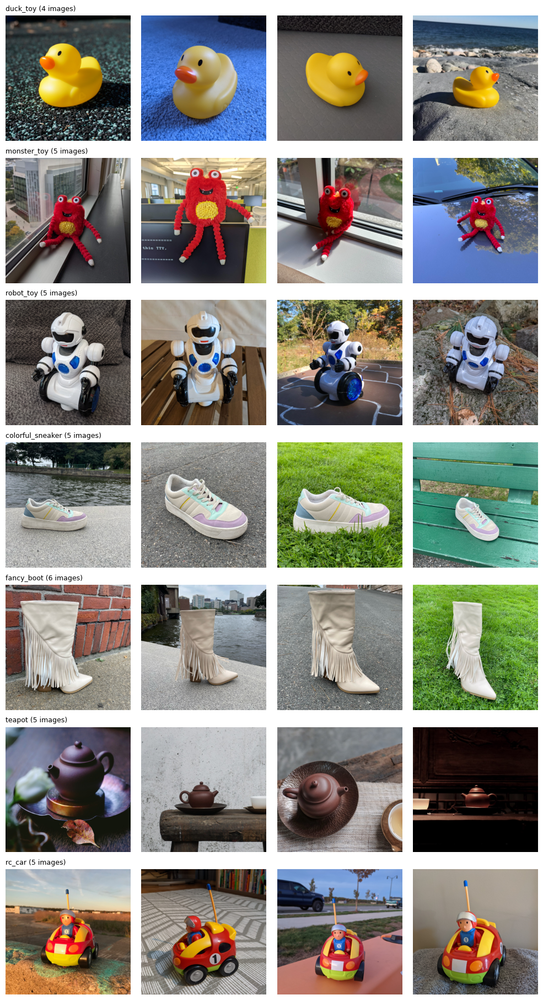

In [4]:
# ============================================================
# LoRA project | Cell 2a: Preview candidate subjects, then choose one
# ============================================================
from huggingface_hub import snapshot_download
import glob
from PIL import Image
import matplotlib.pyplot as plt

CANDIDATES = ['duck_toy', 'monster_toy', 'robot_toy', 'colorful_sneaker', 'fancy_boot', 'teapot', 'rc_car']
local = snapshot_download(repo_id='google/dreambooth', repo_type='dataset',
                          allow_patterns=[f'dataset/{c}/*' for c in CANDIDATES])

fig, axes = plt.subplots(len(CANDIDATES), 4, figsize=(10, 2.6 * len(CANDIDATES)))
for row, c in zip(axes, CANDIDATES):
    files = sorted(glob.glob(f'{local}/dataset/{c}/*'))
    for ax, f in zip(row, files[:4]):
        ax.imshow(Image.open(f)); ax.axis('off')
    row[0].set_title(f'{c} ({len(files)} images)', fontsize=9, loc='left')
plt.tight_layout()
plt.show()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

=== references_and_licenses.txt: lines mentioning monster_toy ===
monster_toy: Photos taken by Varun Jampani

=== prompts_and_classes.txt (first 15 lines) ===
Classes

subject_name,class
backpack,backpack
backpack_dog,backpack
bear_plushie,stuffed animal
berry_bowl,bowl
can,can
candle,candle
cat,cat
cat2,cat
clock,clock
colorful_sneaker,sneaker
dog,dog
dog2,dog

Images found: 5


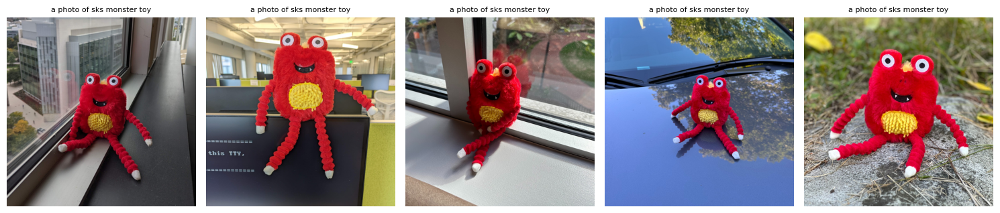

Saved 5 processed images and captions.


In [5]:
# ============================================================
# LoRA project | Cell 2: Download monster_toy, check license, prepare
# ============================================================
import os, glob, json, shutil
from huggingface_hub import snapshot_download
from PIL import Image
import matplotlib.pyplot as plt

SUBJECT = 'monster_toy'
TRIGGER = 'sks monster toy'
CAPTION = 'a photo of {trigger}'
RES = 512

local = snapshot_download(repo_id='google/dreambooth', repo_type='dataset',
                          allow_patterns=[f'dataset/{SUBJECT}/*',
                                          'dataset/references_and_licenses.txt',
                                          'dataset/prompts_and_classes.txt'])

# ---- 1. Read the license and class information BEFORE using the images ----
print(f'=== references_and_licenses.txt: lines mentioning {SUBJECT} ===')
ref = open(f'{local}/dataset/references_and_licenses.txt').read()
keys = {SUBJECT, SUBJECT.replace('_', ' '), SUBJECT.split('_')[0]}
hits = [l for l in ref.splitlines() if any(k in l.lower() for k in keys)]
print('\n'.join(hits) if hits else
      '(no direct match; printing the first 40 lines)\n' + '\n'.join(ref.splitlines()[:40]))
print('\n=== prompts_and_classes.txt (first 15 lines) ===')
print('\n'.join(open(f'{local}/dataset/prompts_and_classes.txt').read().splitlines()[:15]))

# ---- 2. Start from clean folders, then copy the images in ----
RAW_DIR, PROC_DIR = f'{PROJECT_DIR}/data/train', f'{PROJECT_DIR}/data/processed'
for d in (RAW_DIR, PROC_DIR):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d, exist_ok=True)
for p in glob.glob(f'{local}/dataset/{SUBJECT}/*'):
    shutil.copy(p, RAW_DIR)

paths = sorted(p for ext in ('jpg', 'jpeg', 'png', 'webp') for p in glob.glob(f'{RAW_DIR}/*.{ext}'))
print('\nImages found:', len(paths))
assert len(paths) >= 3, 'Download failed or the folder is empty. Paste the output here.'

# ---- 3. Crop to a center square, resize, caption ----
def center_crop_resize(im, res):
    w, h = im.size; s = min(w, h)
    return im.crop(((w - s)//2, (h - s)//2, (w + s)//2, (h + s)//2)).resize((res, res), Image.LANCZOS)

records = []
for i, p in enumerate(paths):
    out = f'{PROC_DIR}/{i:03d}.png'
    center_crop_resize(Image.open(p).convert('RGB'), RES).save(out)
    records.append({'file': out, 'caption': CAPTION.format(trigger=TRIGGER), 'source': os.path.basename(p)})
json.dump(records, open(f'{PROJECT_DIR}/data/captions.json', 'w'), indent=2)

fig, axes = plt.subplots(1, len(records), figsize=(3 * len(records), 3.4))
axes = [axes] if len(records) == 1 else axes
for ax, r in zip(axes, records):
    ax.imshow(Image.open(r['file'])); ax.axis('off'); ax.set_title(r['caption'], fontsize=8)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/dataset_preview.png', dpi=110)
plt.show()
print('Saved', len(records), 'processed images and captions.')

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


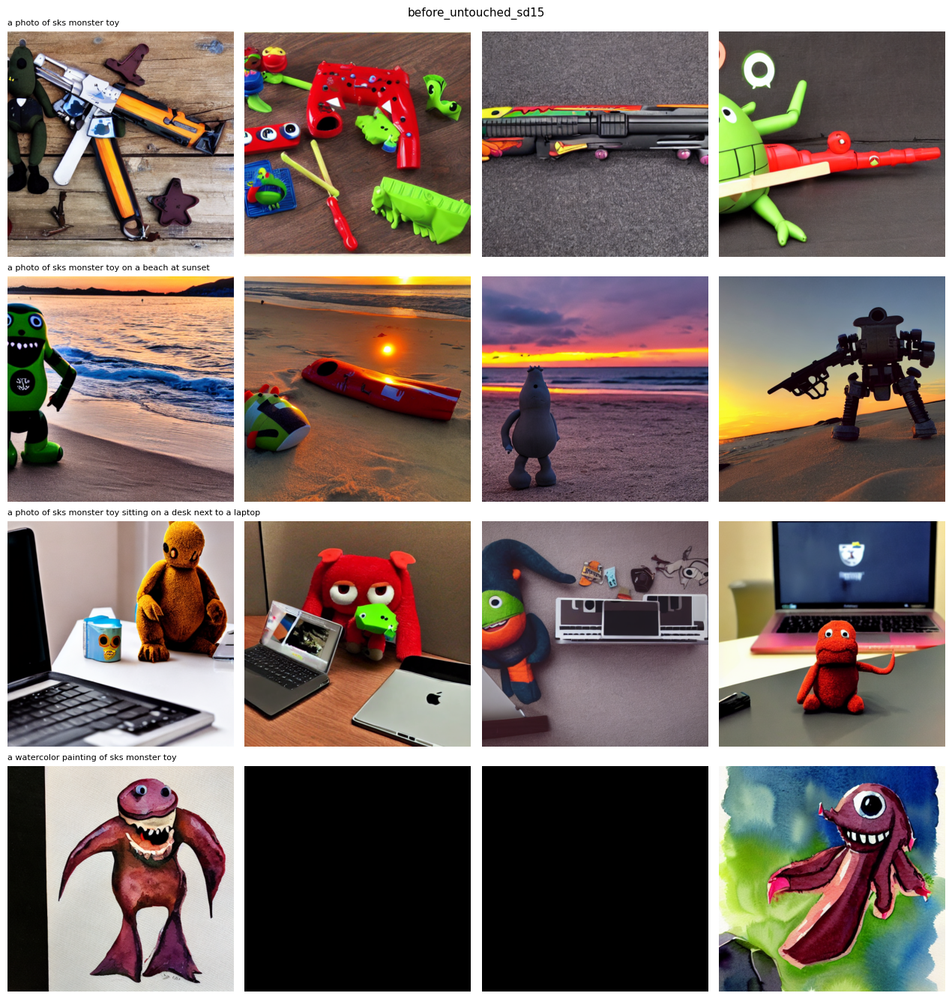

before_untouched_sd15: 16 images in 82 s


In [6]:
# ============================================================
# LoRA project | Cell 3: "Before" images (untouched Stable Diffusion 1.5)
# ============================================================
import time, json
import matplotlib.pyplot as plt

EVAL_PROMPTS = [
    'a photo of sks monster toy',
    'a photo of sks monster toy on a beach at sunset',
    'a photo of sks monster toy sitting on a desk next to a laptop',
    'a watercolor painting of sks monster toy',
]
EVAL_SEEDS = [0, 1, 2, 3]
json.dump({'prompts': EVAL_PROMPTS, 'seeds': EVAL_SEEDS, 'steps': 30, 'guidance': 7.5},
          open(f'{PROJECT_DIR}/outputs/eval_settings.json', 'w'), indent=2)

def generate_grid(pipe, tag, **kwargs):
    """Same prompts and seeds every time, so before/after images are comparable."""
    t0 = time.time()
    imgs = []
    for pr in EVAL_PROMPTS:
        row = []
        for s in EVAL_SEEDS:
            g = torch.Generator(device=device).manual_seed(s)
            row.append(pipe(pr, num_inference_steps=30, guidance_scale=7.5,
                            generator=g, **kwargs).images[0])
        imgs.append(row)
    fig, axes = plt.subplots(len(EVAL_PROMPTS), len(EVAL_SEEDS), figsize=(3.2 * len(EVAL_SEEDS), 3.4 * len(EVAL_PROMPTS)))
    for r, row in enumerate(imgs):
        for c, im in enumerate(row):
            axes[r, c].imshow(im); axes[r, c].axis('off')
            if c == 0:
                axes[r, c].set_title(EVAL_PROMPTS[r], fontsize=8, loc='left')
    plt.suptitle(tag, fontsize=11)
    plt.tight_layout()
    plt.savefig(f'{PROJECT_DIR}/outputs/{tag}.png', dpi=110)
    plt.show()
    print(f'{tag}: {len(EVAL_PROMPTS) * len(EVAL_SEEDS)} images in {time.time() - t0:.0f} s')
    return imgs

before_imgs = generate_grid(pipe, 'before_untouched_sd15')

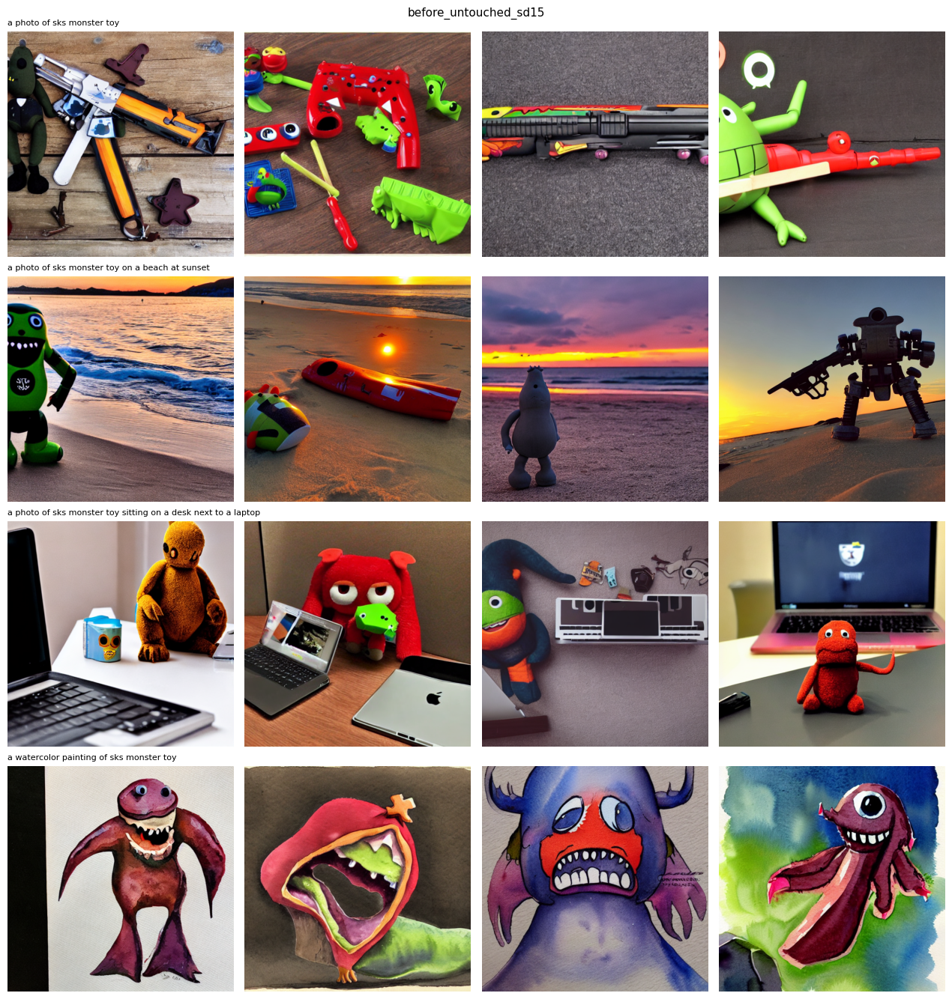

before_untouched_sd15: 16 images in 89 s


In [7]:
# ============================================================
# LoRA project | Cell 3b: evaluation pipeline without the safety-filter false positives
# ============================================================
from diffusers import StableDiffusionPipeline

def make_eval_pipe(unet):
    """Same components as the main pipe; safety filter off ONLY for the fixed benign eval prompts."""
    return StableDiffusionPipeline(
        vae=pipe.vae, text_encoder=pipe.text_encoder, tokenizer=pipe.tokenizer,
        unet=unet, scheduler=pipe.scheduler,
        safety_checker=None, feature_extractor=None, requires_safety_checker=False)

before_pipe = make_eval_pipe(pipe.unet)          # pipe.unet is still the untouched model
before_pipe.set_progress_bar_config(disable=True)
before_imgs = generate_grid(before_pipe, 'before_untouched_sd15')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


[monster_r8] rank 8 | trainable 1.59 M of 860 M (0.19%)
step   50 | loss 0.1645 | 0.8 min
step  100 | loss 0.1379 | 1.6 min
step  150 | loss 0.1445 | 2.4 min
step  200 | loss 0.1356 | 3.1 min
step  250 | loss 0.1489 | 3.9 min
step  300 | loss 0.1336 | 4.6 min
step  350 | loss 0.1107 | 5.3 min
step  400 | loss 0.1393 | 6.1 min
step  450 | loss 0.1094 | 6.8 min
step  500 | loss 0.1131 | 7.6 min
step  550 | loss 0.1269 | 8.3 min
step  600 | loss 0.1285 | 9.1 min

STATS: {
  "name": "monster_r8",
  "rank": 8,
  "steps": 600,
  "lr": 0.0001,
  "batch_size": 2,
  "trainable_M": 1.594368,
  "base_M": 859.520964,
  "trainable_pct": 0.18549495204633543,
  "minutes": 9.082171936829885,
  "peak_mem_gb": 5.36215296,
  "adapter_file_mb": 6.414992,
  "final_loss": 0.1285360276978463
}


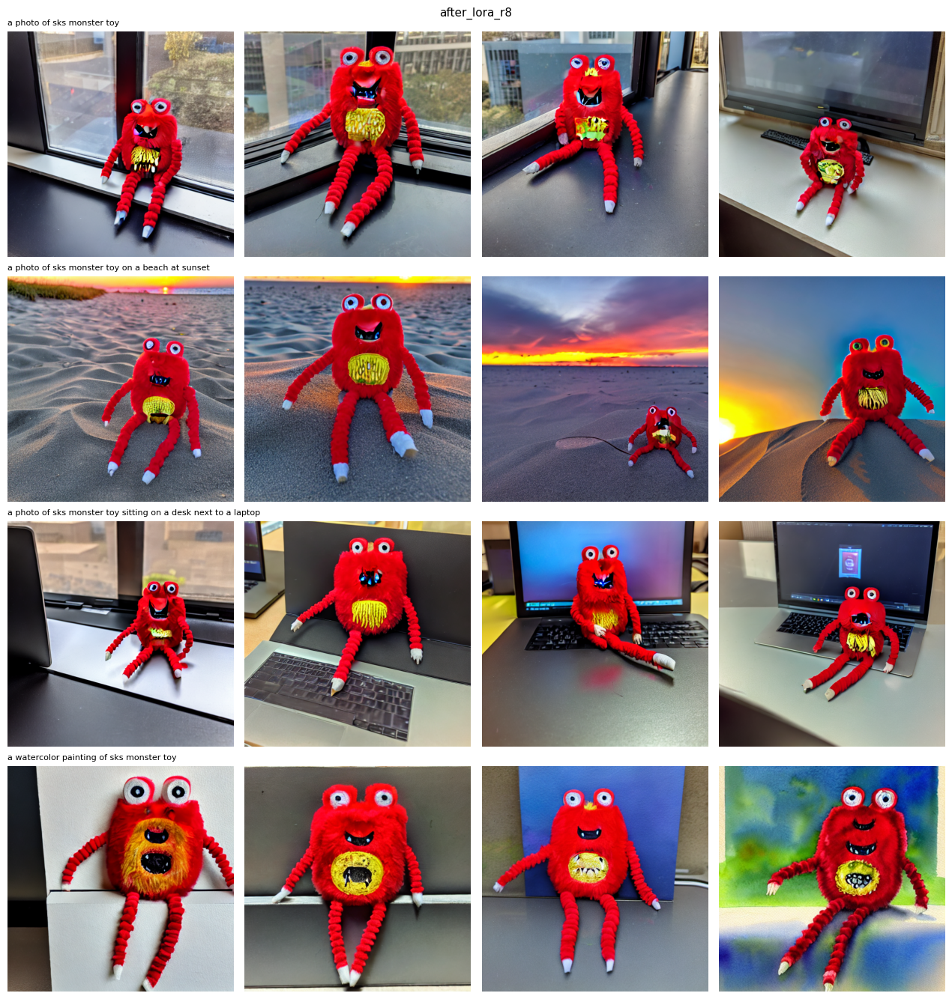

after_lora_r8: 16 images in 109 s


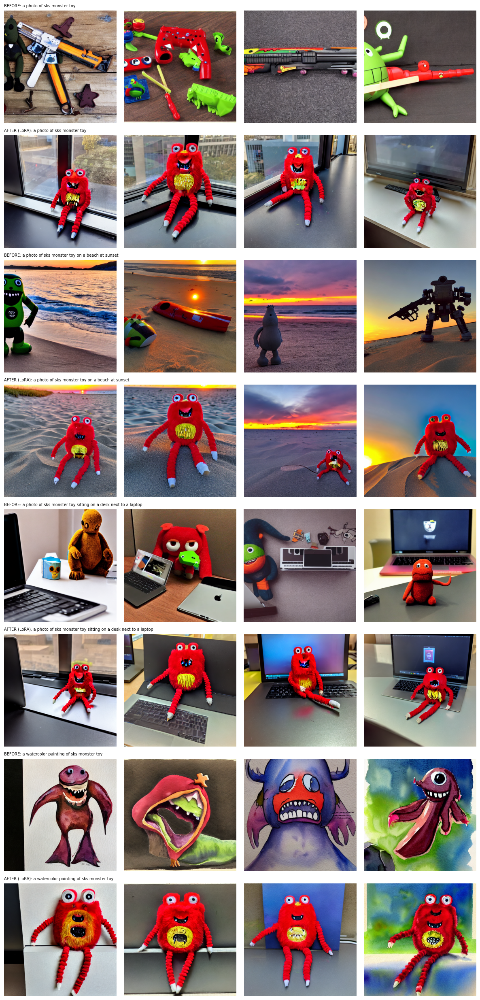

In [8]:
# ============================================================
# LoRA project | Cell 4: LoRA training (SD 1.5, attention layers) + "after" grid
# ============================================================
import time, json, os
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import UNet2DConditionModel, DDPMScheduler
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict

def load_train_data():
    recs = json.load(open(f'{PROJECT_DIR}/data/captions.json'))
    imgs = [torch.from_numpy(np.array(Image.open(r['file']).convert('RGB'))).permute(2, 0, 1).float() / 127.5 - 1
            for r in recs]
    return torch.stack(imgs).half().to(device), recs[0]['caption']

def train_lora(rank=8, steps=600, lr=1e-4, bs=2, name='monster_r8', seed=42):
    set_seed(seed)
    data, caption = load_train_data()
    N = len(data)
    sched = DDPMScheduler.from_pretrained(MODEL_ID, subfolder='scheduler')
    tok, text_enc, vae = pipe.tokenizer, pipe.text_encoder, pipe.vae

    # Fresh copy of the base UNet, frozen, with LoRA adapters on the attention layers
    unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder='unet', torch_dtype=torch.float16).to(device)
    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank,
                                target_modules=['to_k', 'to_q', 'to_v', 'to_out.0']))
    for p in unet.parameters():
        if p.requires_grad:
            p.data = p.data.float()                   # trainable LoRA weights in fp32
    unet.enable_gradient_checkpointing()
    unet.train()

    params = [p for p in unet.parameters() if p.requires_grad]
    n_train = sum(p.numel() for p in params)
    n_base = sum(p.numel() for p in unet.parameters()) - n_train
    print(f'[{name}] rank {rank} | trainable {n_train / 1e6:.2f} M of {n_base / 1e6:.0f} M '
          f'({100 * n_train / n_base:.2f}%)')

    ids = tok(caption, padding='max_length', max_length=tok.model_max_length,
              truncation=True, return_tensors='pt').input_ids.to(device)
    with torch.no_grad():
        emb = text_enc(ids)[0]                         # same caption for every image

    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)
    scaler = torch.amp.GradScaler('cuda')
    torch.cuda.reset_peak_memory_stats()
    t0, running, losses = time.time(), [], []

    for step in range(1, steps + 1):
        x = data[torch.randint(0, N, (bs,))]
        flip = (torch.rand(bs, device=device) < 0.5).view(-1, 1, 1, 1)
        x = torch.where(flip, x.flip(-1), x)           # random horizontal flip
        with torch.no_grad():
            latents = vae.encode(x).latent_dist.sample() * vae.config.scaling_factor
        noise = torch.randn_like(latents)
        t = torch.randint(0, sched.config.num_train_timesteps, (bs,), device=device)
        noisy = sched.add_noise(latents, noise, t)
        with torch.autocast('cuda', dtype=torch.float16):
            pred = unet(noisy, t, encoder_hidden_states=emb.expand(bs, -1, -1)).sample
        loss = F.mse_loss(pred.float(), noise.float())  # same noise-prediction loss as project 1

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update()
        running.append(loss.item())
        if step % 50 == 0:
            losses.append((step, float(np.mean(running)))); running = []
            print(f'step {step:4d} | loss {losses[-1][1]:.4f} | {(time.time() - t0) / 60:.1f} min')

    minutes = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_allocated() / 1e9
    unet.eval()

    # Save only the adapter weights (a few MB)
    out_dir = f'{PROJECT_DIR}/lora_weights/{name}'
    os.makedirs(out_dir, exist_ok=True)
    sd = get_peft_model_state_dict(unet)
    try:
        StableDiffusionPipeline.save_lora_weights(out_dir, unet_lora_layers=convert_state_dict_to_diffusers(sd),
                                                  safe_serialization=True)
    except Exception as e:
        print('save_lora_weights failed, saving raw state dict instead:', str(e)[:120])
        torch.save(sd, f'{out_dir}/lora_state.pt')
    size_mb = sum(os.path.getsize(os.path.join(out_dir, f)) for f in os.listdir(out_dir)) / 1e6

    stats = dict(name=name, rank=rank, steps=steps, lr=lr, batch_size=bs, trainable_M=n_train / 1e6,
                 base_M=n_base / 1e6, trainable_pct=100 * n_train / n_base, minutes=minutes,
                 peak_mem_gb=peak, adapter_file_mb=size_mb, final_loss=losses[-1][1])
    json.dump(dict(stats=stats, losses=losses), open(f'{PROJECT_DIR}/outputs/{name}_summary.json', 'w'), indent=2)
    print('\nSTATS:', json.dumps(stats, indent=2))
    return unet, stats, losses

def compare_grid(before, after, tag):
    """Rows alternate: before (top), after (bottom) for each prompt; columns = seeds."""
    R, C = len(EVAL_PROMPTS), len(EVAL_SEEDS)
    fig, axes = plt.subplots(2 * R, C, figsize=(3 * C, 3.1 * 2 * R))
    for r in range(R):
        for c in range(C):
            for k, (imgs, lab) in enumerate([(before, 'BEFORE'), (after, 'AFTER (LoRA)')]):
                ax = axes[2 * r + k, c]
                ax.imshow(imgs[r][c]); ax.axis('off')
                if c == 0:
                    ax.set_title(f'{lab}: {EVAL_PROMPTS[r]}', fontsize=7, loc='left')
    plt.tight_layout()
    plt.savefig(f'{PROJECT_DIR}/outputs/{tag}.png', dpi=100)
    plt.show()

# ---- Train, then generate the AFTER images with the same prompts and seeds ----
lora_unet, stats, losses = train_lora(rank=8, steps=600, lr=1e-4, bs=2, name='monster_r8')
after_pipe = make_eval_pipe(lora_unet)
after_pipe.set_progress_bar_config(disable=True)
after_imgs = generate_grid(after_pipe, 'after_lora_r8')
compare_grid(before_imgs, after_imgs, 'before_vs_after_r8')

In [ ]:
# ============================================================
# LoRA project | Cell 5: Rank experiment (4 / 8 / 16) + leakage test
# ============================================================
import gc, pandas as pd

DRIFT_PROMPT = 'a photo of a plush toy on a table'        # no trigger word
EXP_PROMPTS = [EVAL_PROMPTS[1], EVAL_PROMPTS[3], DRIFT_PROMPT]   # beach, watercolor, no-trigger

def gen_rows(p, prompts):
    rows = []
    for pr in prompts:
        row = []
        for s in EVAL_SEEDS:
            g = torch.Generator(device=device).manual_seed(s)
            row.append(p(pr, num_inference_steps=30, guidance_scale=7.5, generator=g).images[0])
        rows.append(row)
    return rows

def cleanup():
    gc.collect(); torch.cuda.empty_cache()

results, all_stats = {}, [stats]                 # stats = rank-8 run from Cell 4
results['base'] = gen_rows(before_pipe, EXP_PROMPTS)
results['r8']   = gen_rows(after_pipe,  EXP_PROMPTS)
del after_pipe, lora_unet; cleanup()             # free GPU memory before more training

for r in (4, 16):
    u, st, _ = train_lora(rank=r, steps=600, lr=1e-4, bs=2, name=f'monster_r{r}')
    p = make_eval_pipe(u); p.set_progress_bar_config(disable=True)
    results[f'r{r}'] = gen_rows(p, EXP_PROMPTS)
    all_stats.append(st)
    del u, p; cleanup()

# ---- Comparison figure: columns = models, rows = prompt x 2 seeds ----
cols = ['base', 'r4', 'r8', 'r16']
titles = ['untouched SD 1.5', 'LoRA rank 4', 'LoRA rank 8', 'LoRA rank 16']
fig, axes = plt.subplots(len(EXP_PROMPTS) * 2, 4, figsize=(12, 3 * len(EXP_PROMPTS) * 2))
for pi, pr in enumerate(EXP_PROMPTS):
    for si in range(2):
        for ci, c in enumerate(cols):
            ax = axes[pi * 2 + si, ci]
            ax.imshow(results[c][pi][si]); ax.axis('off')
            if pi == 0 and si == 0:
                ax.set_title(titles[ci], fontsize=10)
        axes[pi * 2 + si, 0].text(-0.02, 0.5, pr[:34] + f' (seed {EVAL_SEEDS[si]})', transform=axes[pi * 2 + si, 0].transAxes,
                                  rotation=90, va='center', ha='right', fontsize=6)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/rank_comparison.png', dpi=100)
plt.show()

df = pd.DataFrame(all_stats).sort_values('rank')[['rank', 'trainable_M', 'trainable_pct', 'minutes',
                                                   'peak_mem_gb', 'adapter_file_mb', 'final_loss']].round(3)
display(df)
df.to_csv(f'{PROJECT_DIR}/outputs/rank_table.csv', index=False)

[monster_r4] rank 4 | trainable 0.80 M of 860 M (0.09%)
step   50 | loss 0.1707 | 0.8 min
step  100 | loss 0.1415 | 1.5 min
step  150 | loss 0.1436 | 2.3 min
step  200 | loss 0.1316 | 3.0 min
step  250 | loss 0.1405 | 3.8 min
step  300 | loss 0.1318 | 4.5 min
step  350 | loss 0.1178 | 5.3 min
step  400 | loss 0.1494 | 6.0 min
step  450 | loss 0.1188 | 6.7 min
step  500 | loss 0.1229 | 7.5 min
step  550 | loss 0.1297 | 8.2 min
step  600 | loss 0.1266 | 9.0 min

STATS: {
  "name": "monster_r4",
  "rank": 4,
  "steps": 600,
  "lr": 0.0001,
  "batch_size": 2,
  "trainable_M": 0.797184,
  "base_M": 859.520964,
  "trainable_pct": 0.09274747602316771,
  "minutes": 8.981052056948345,
  "peak_mem_gb": 5.349135872,
  "adapter_file_mb": 3.226184,
  "final_loss": 0.12656770643778145
}
[monster_r16] rank 16 | trainable 3.19 M of 860 M (0.37%)
step   50 | loss 0.1631 | 0.8 min
step  100 | loss 0.1402 | 1.5 min
step  150 | loss 0.1433 | 2.3 min
step  200 | loss 0.1381 | 3.0 min
step  250 | loss 0.139